# **Filtrado de señal EMG del gastrocnemio frente a una fuerza contraria**
Se configura la señal A1 que es donde está conectado el sensor de EMG en los metadatos.

In [25]:
import os, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import signal
import pywt

plt.rcParams.update({"figure.figsize": (14, 4), "axes.grid": True, "grid.alpha": 0.3, "font.size": 11})
rng = np.random.default_rng(seed=42)

# Lectura de datos
RUTA_ARCHIVO = "gastrocnemio_f_contrario.txt"
lineas_cabecera = []
with open(RUTA_ARCHIVO, "r", encoding="utf-8", errors="ignore") as archivo:
    for linea in archivo:
        if linea.startswith("#"): lineas_cabecera.append(linea.strip())
        else: break

contenido = lineas_cabecera[1].lstrip("#").strip()
metadatos = list(json.loads(contenido).values())[0]

Fs = int(metadatos.get("sampling rate", 1000))
columnas = metadatos.get("column", ["nSeq", "I1", "I2", "O1", "O2", "A1"])
resolucion_A1 = metadatos.get("resolution", [10, 10, 10, 10, 10, 10])[columnas.index("A1")]

datos = pd.read_csv(RUTA_ARCHIVO, sep=r"\s+", comment="#", header=None).iloc[:, :len(columnas)]
datos.columns = columnas


# **Conversión de ADC a Microvoltios (mV) y centrado de la señal**
Esta etapa transforma las lecturas crudas del dispositivo BITalino en unidades físicas de voltaje y acondiciona la señal para su posterior filtrado, esta acción se realiza mediante la elimincación de la línea base u offset en DC.

In [26]:
VCC, G_EMG = 3.3, 1009  # Ganancia EMG BITalino = 1009
emg_adc = datos["A1"].to_numpy(dtype=float)

emg_mV = ((emg_adc / 2**resolucion_A1) - 0.5) * VCC / G_EMG * 1000
emg_original = emg_mV - np.mean(emg_mV)
t = np.arange(len(emg_original)) / Fs


# **Contaminación artificial se la señal**
Aqui se añaden condiciones de interferencia electromagnetica y ruido instrumental sobre la EMG, tomando como base la metodología empleada originalmente para el ECG analizado en clase.
Se añaden dos componentes sinusoidales: 60 Hz (frecuencia fundamental de red electrica) y 120 Hz (primer armónico derivado de fuentes de alimentación)

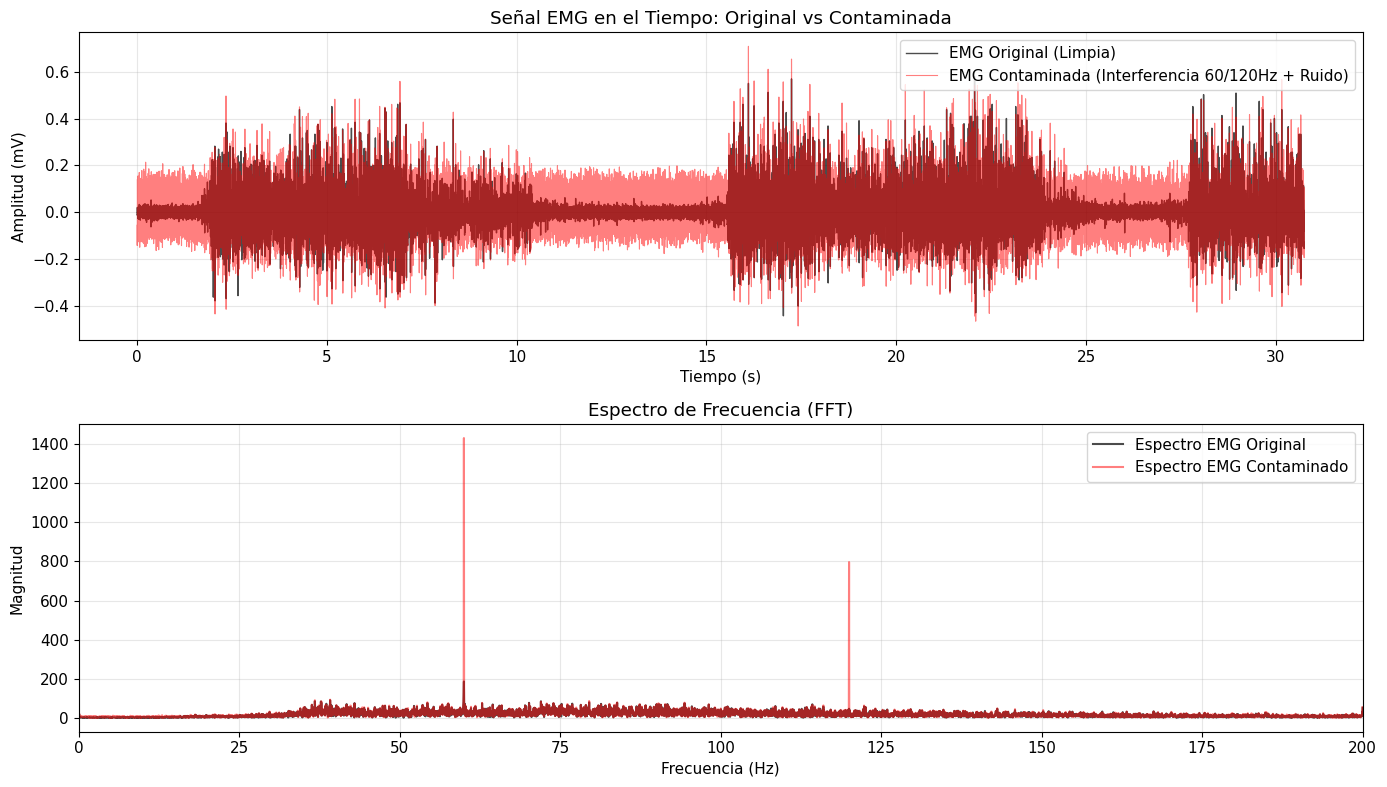

In [27]:
f1, f2 = 60, 120
escala = np.std(emg_original)
a1, a2, sigma = 1.0 * escala, 0.6 * escala, 0.3 * escala
fase_1, fase_2 = rng.uniform(0, 2 * np.pi, size=2)

ruido_s1 = a1 * np.sin(2 * np.pi * f1 * t + fase_1)
ruido_s2 = a2 * np.sin(2 * np.pi * f2 * t + fase_2)
ruido_g = rng.normal(0, sigma, size=len(t))

emg_contaminado = emg_original + ruido_s1 + ruido_s2 + ruido_g

plt.figure(figsize=(14, 8))

# Señal temporal original vs contaminada
plt.subplot(2, 1, 1)
plt.plot(t, emg_original, label="EMG Original (Limpia)", color="black", alpha=0.7, linewidth=1)
plt.plot(t, emg_contaminado, label="EMG Contaminada (Interferencia 60/120Hz + Ruido)", color="red", alpha=0.5, linewidth=0.8)
plt.title("Señal EMG en el Tiempo: Original vs Contaminada")
plt.xlabel("Tiempo (s)")
plt.ylabel("Amplitud (mV)")
plt.legend(loc="upper right")

# Espectro de Frecuencia (FFT)
plt.subplot(2, 1, 2)
freqs = np.fft.rfftfreq(len(t), d=1/Fs)
fft_orig = np.abs(np.fft.rfft(emg_original))
fft_cont = np.abs(np.fft.rfft(emg_contaminado))

plt.plot(freqs, fft_orig, label="Espectro EMG Original", color="black", alpha=0.7)
plt.plot(freqs, fft_cont, label="Espectro EMG Contaminado", color="red", alpha=0.5)
plt.title("Espectro de Frecuencia (FFT)")
plt.xlabel("Frecuencia (Hz)")
plt.ylabel("Magnitud")
plt.xlim(0, 200) #zona de ruido principal
plt.legend(loc="upper right")

plt.tight_layout()
plt.show()


## **Técnicas de Filtrado Aplicadas**

### **A. Filtro Pasa-banda Butterworth**
Se aplica para resaltar la actividad muscular real dentro del rango de 20 Hz a 450 Hz, que es donde se concentra la información electromiográfica más relevante. Al mismo tiempo, suprime las bajas frecuencias asociadas a movimientos de electrodos o cables y reduce el ruido de alta frecuencia ajeno a la fisiología muscular.

### **B. Filtros Rechaza-banda / Notch**
Estos filtros eliminan de manera precisa la interferencia de la red eléctrica en 60 Hz y su primer armónico en 120 Hz, evitando que estas frecuencias contaminen la señal muscular. Al aplicarse en ambas direcciones, se asegura que la señal no sufra distorsiones en el tiempo.

### **C. Filtro Adaptativo LMS (Least Mean Squares)**
Este filtro se adapta dinámicamente para identificar y cancelar la interferencia eléctrica en 60 Hz y 120 Hz. Lo hace ajustando sus parámetros en cada iteración, de modo que la señal resultante conserve únicamente la actividad muscular limpia.

### **D. Desruidado mediante Transformada Wavelet (Denoising) e Enfoque Híbrido**
La técnica Wavelet permite separar el ruido de la señal muscular en diferentes escalas de frecuencia. Se aplica un umbral suave para reducir el ruido gaussiano sin perder información relevante. En el enfoque híbrido, primero se eliminan las interferencias tonales (60/120 Hz) con el filtro Notch y luego se aplica el desruidado Wavelet.



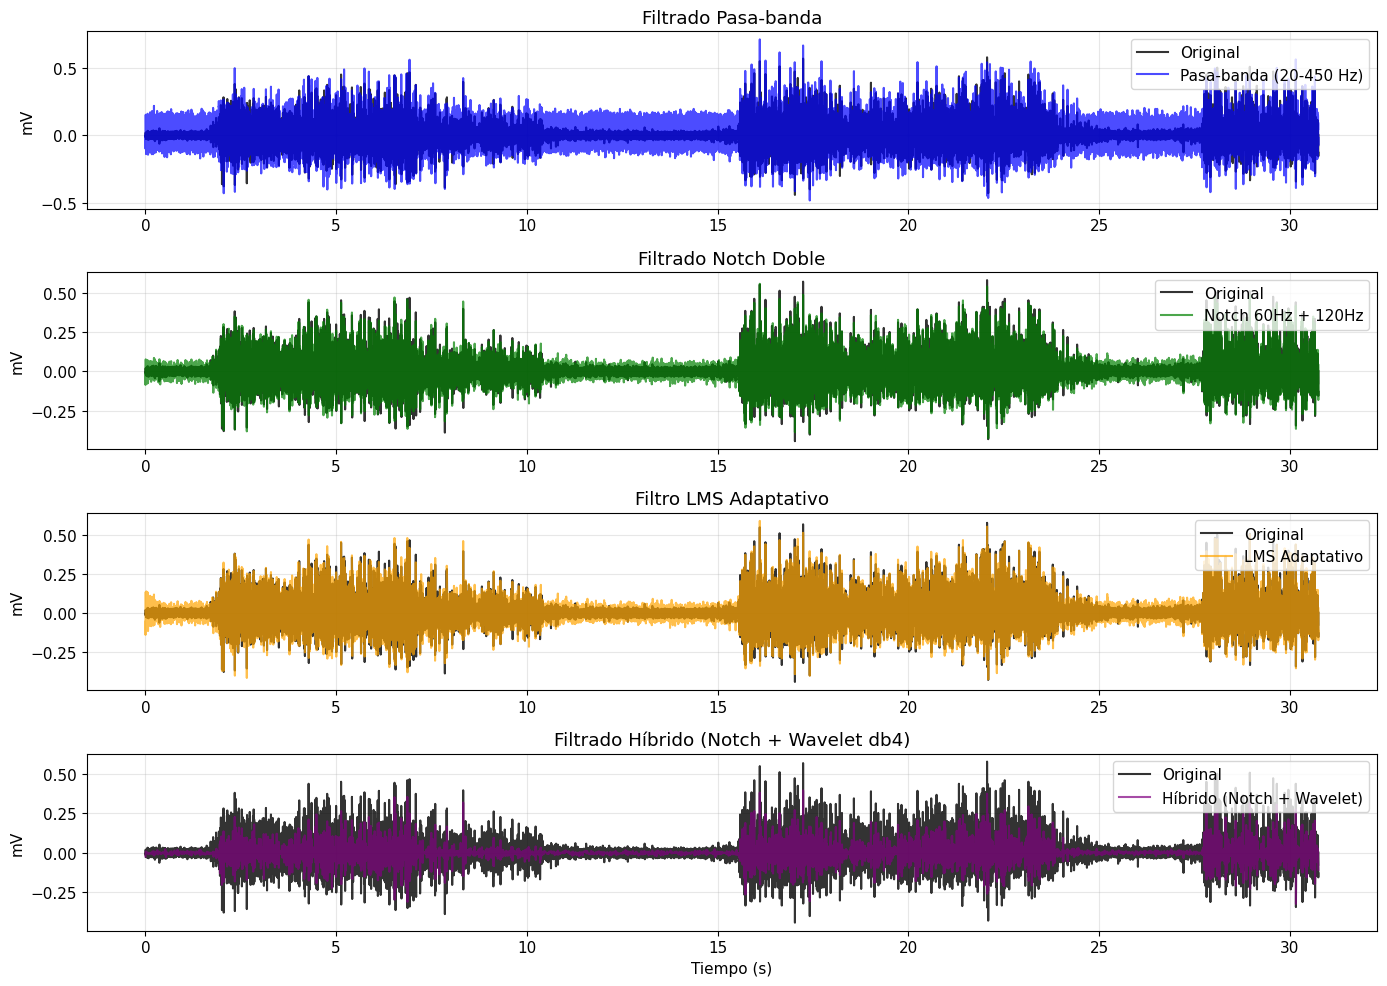

In [28]:
# Pasabanda EMG (20-450 Hz)
sos_pb = signal.butter(4, [20.0, 450.0], btype="bandpass", fs=Fs, output="sos")
emg_pasabanda = signal.sosfiltfilt(sos_pb, emg_contaminado)

# Filtros Notch (60 Hz y 120 Hz)
b1, a1_n = signal.iirnotch(f1, Q=30, fs=Fs)
b2, a2_n = signal.iirnotch(f2, Q=30, fs=Fs)
emg_notch_f1 = signal.filtfilt(b1, a1_n, emg_contaminado)
emg_notch_f1f2 = signal.filtfilt(b2, a2_n, emg_notch_f1)

# Filtro LMS Adaptativo
def filtro_lms(d, referencias, mu=0.005):
    N, M = referencias.shape
    w, y, e = np.zeros(M), np.zeros(N), np.zeros(N)
    for n in range(N):
        x_n = referencias[n]
        y[n] = w @ x_n
        e[n] = d[n] - y[n]
        w = w + 2 * mu * e[n] * x_n
    return e

ref_lms = np.column_stack([
    np.sin(2 * np.pi * f1 * t), np.cos(2 * np.pi * f1 * t),
    np.sin(2 * np.pi * f2 * t), np.cos(2 * np.pi * f2 * t)
])
emg_lms = filtro_lms(emg_contaminado, ref_lms, mu=0.005)

# Desruidado Wavelet
def denoising_wavelet(x, wavelet="db4", nivel=4):
    coefs = pywt.wavedec(x, wavelet, level=nivel)
    sigma = np.median(np.abs(coefs[-1])) / 0.6745
    umbral = sigma * np.sqrt(2 * np.log(len(x)))
    coefs_u = [coefs[0]] + [pywt.threshold(c, umbral, mode="soft") for c in coefs[1:]]
    return pywt.waverec(coefs_u, wavelet)[:len(x)]

emg_wavelet = denoising_wavelet(emg_contaminado, nivel=4)
emg_hibrido = denoising_wavelet(emg_notch_f1f2, nivel=4)


plt.figure(figsize=(14, 10))

plt.subplot(4, 1, 1)
plt.plot(t, emg_original, color="black", label="Original", alpha=0.8)
plt.plot(t, emg_pasabanda, color="blue", label="Pasa-banda (20-450 Hz)", alpha=0.7)
plt.title("Filtrado Pasa-banda")
plt.ylabel("mV")
plt.legend(loc="upper right")

plt.subplot(4, 1, 2)
plt.plot(t, emg_original, color="black", label="Original", alpha=0.8)
plt.plot(t, emg_notch_f1f2, color="green", label="Notch 60Hz + 120Hz", alpha=0.7)
plt.title("Filtrado Notch Doble")
plt.ylabel("mV")
plt.legend(loc="upper right")

plt.subplot(4, 1, 3)
plt.plot(t, emg_original, color="black", label="Original", alpha=0.8)
plt.plot(t, emg_lms, color="orange", label="LMS Adaptativo", alpha=0.7)
plt.title("Filtro LMS Adaptativo")
plt.ylabel("mV")
plt.legend(loc="upper right")

plt.subplot(4, 1, 4)
plt.plot(t, emg_original, color="black", label="Original", alpha=0.8)
plt.plot(t, emg_hibrido, color="purple", label="Híbrido (Notch + Wavelet)", alpha=0.7)
plt.title("Filtrado Híbrido (Notch + Wavelet db4)")
plt.xlabel("Tiempo (s)")
plt.ylabel("mV")
plt.legend(loc="upper right")

plt.tight_layout()
plt.show()




## **Métricas y Tabla de Evaluación**

En esta etapa se cuantifica cuantitativamente la eficacia de cada método de filtrado comparando las señales estimadas contra la señal EMG original limpia. Para evitar los efectos de borde causados por los transitorios de respuesta al impulso de los filtros, las métricas se calculan exclusivamente dentro de la ventana de evaluación temporal definida por la máscara `evaluacion = (t >= 0.1) & (t <= t[-1] - 0.1)`

---
#### Relación señal-ruido (SNR)
El SNR mide la proporción entre la potencia de la señal útil (EMG original) y la potencia del ruido o error remanente tras el proceso de filtrado:

  * Un valor de SNR más alto (en dB) indica un mejor desempeño del filtro, lo que significa que el método logró eliminar las interferencias dejando la señal muscular casi intacta.
  * Si el SNR es muy bajo o negativo, la energía del error/ruido supera a la energía de la señal mioeléctrica útil.

#### Raíz del Error Cuadrático Medio (RMSE - *Root Mean Square Error*)
Mide la magnitud promedio de la desviación física entre la señal filtrada y la original:

Un RMSE cercano a 0 mV indica una reconstrucción casi perfecta en amplitud de la contracción muscular.

#### Coeficiente de Correlación de Pearson ($r$)

Un valor de $r \approx 1.0$ confirma que el filtro conservó la forma del patrón de contracción del gastrocnemio sin deformar sus picos ni inducir retrasos de fase.


,RMSE (mV),SNR (dB),Correlación r,Mejora SNR vs contaminado (dB)
B2 – Notch 60+120 Hz,0.0309,8.4999,0.9288,7.3384
LMS adaptativo,0.0317,8.2714,0.9280,7.1098
B1 – Notch 60 Hz,0.0455,5.1467,0.8672,3.9851
Wavelet (denoising),0.0538,3.6799,0.7562,2.5184
Híbrido notch + Wavelet,0.0541,3.6341,0.8100,2.4725
A – Pasa-banda,0.0714,1.2330,0.7793,0.0714
Contaminado (sin filtrar),0.0719,1.1616,0.7781,0.0000


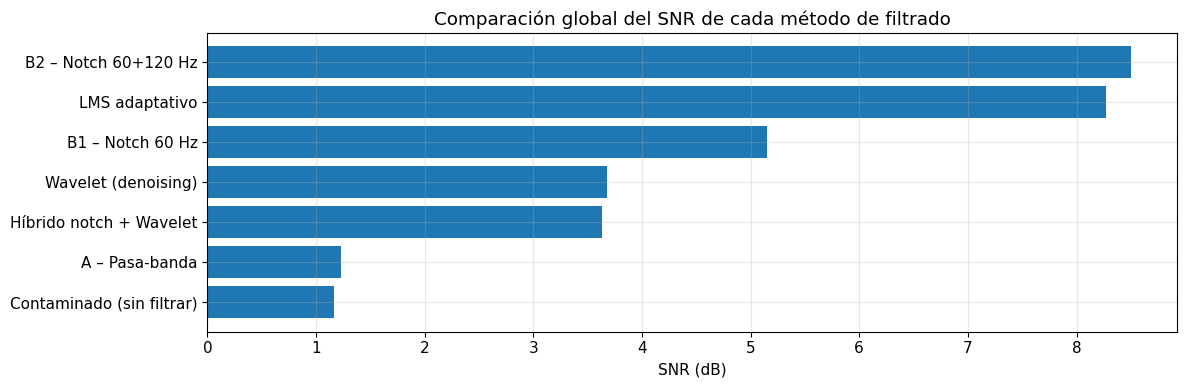

In [29]:

evaluacion = (t >= 0.1) & (t <= t[-1] - 0.1)

def calcular_metricas(referencia, estimada, mascara=evaluacion):
    x, y = referencia[mascara], estimada[mascara]
    error = y - x
    rmse = np.sqrt(np.mean(error ** 2))
    snr = 10 * np.log10(np.sum(x ** 2) / np.sum(error ** 2))
    r = np.corrcoef(x, y)[0, 1]
    return {"RMSE (mV)": rmse, "SNR (dB)": snr, "Correlación r": r}

resultados = {
    "Contaminado (sin filtrar)": calcular_metricas(emg_original, emg_contaminado),
    "A – Pasa-banda":            calcular_metricas(emg_original, emg_pasabanda),
    f"B1 – Notch {f1} Hz":       calcular_metricas(emg_original, emg_notch_f1),
    f"B2 – Notch {f1}+{f2} Hz":  calcular_metricas(emg_original, emg_notch_f1f2),
    "LMS adaptativo":            calcular_metricas(emg_original, emg_lms),
    "Wavelet (denoising)":       calcular_metricas(emg_original, emg_wavelet),
    "Híbrido notch + Wavelet":   calcular_metricas(emg_original, emg_hibrido),
}

tabla_final = pd.DataFrame(resultados).T
tabla_final["Mejora SNR vs contaminado (dB)"] = (
    tabla_final["SNR (dB)"] - tabla_final.loc["Contaminado (sin filtrar)", "SNR (dB)"]
)

# Tabla
display(tabla_final.round(4).sort_values("SNR (dB)", ascending=False))

# Grafico de barras
plt.figure(figsize=(12, 4))
orden = tabla_final.sort_values("SNR (dB)")
plt.barh(orden.index, orden["SNR (dB)"], color="tab:blue")
plt.xlabel("SNR (dB)")
plt.title("Comparación global del SNR de cada método de filtrado")
plt.tight_layout()
plt.show()

## **Conclusión**
En conclusión, el doble filtro Notch demostró ser la técnica más efectiva para limpiar la señal EMG, alcanzando la mayor mejora en calidad y preservando la morfología muscular. El filtro LMS adaptativo se posiciona como una alternativa sólida para aplicaciones en tiempo real gracias a su capacidad de ajuste dinámico. Los métodos basados en Wavelet, aunque útiles para reducir ruido gaussiano, mostraron limitaciones por el sobre‑suavizado de la señal. Finalmente, el pasa‑banda aislado resultó insuficiente frente a la interferencia tonal de la red eléctrica, confirmando que no es adecuado como única estrategia de filtrado.
